In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Polygon, Patch, FancyArrowPatch
from pathlib import Path
import yaml

MAPS_DIR = Path("../maps")

def load_map_image(track_name):
    """Load the map image and its origin/resolution from the YAML."""
    track_dir = MAPS_DIR / f"{track_name}_10489"
    img_path = track_dir / f"{track_name}_map.png"
    yaml_path = track_dir / f"{track_name}_map.yaml"

    img = mpimg.imread(str(img_path))
    with open(yaml_path) as f:
        meta = yaml.safe_load(f)

    origin = meta["origin"]  # [x, y, theta]
    resolution = meta["resolution"]  # m/pixel
    return img, origin, resolution

def load_centerline(track_name):
    """Load centerline: x, y, w_right, w_left."""
    path = MAPS_DIR / f"{track_name}_10489" / f"{track_name}_centerline.csv"
    data = np.loadtxt(str(path), delimiter=',', skiprows=1)
    return data  # columns: x, y, w_right, w_left

def load_raceline(track_name):
    """Load raceline: s, x, y, psi, kappa, vx, ax."""
    path = MAPS_DIR / f"{track_name}_10489" / f"traj_race_cl_centerline_mintime_mue1.0489_{track_name}_map.csv"
    data = np.loadtxt(str(path), delimiter=';', skiprows=3)
    return data  # columns: s, x, y, psi, kappa, vx, ax

def load_start_pose(track_name):
    """Load starting pose (sx, sy, stheta) from map config YAML."""
    path = MAPS_DIR / f"config_{track_name}_map.yaml"
    with open(path) as f:
        cfg = yaml.safe_load(f)
    return cfg["sx"], cfg["sy"], cfg["stheta"]

def compute_track_boundaries(centerline_data):
    """Compute inner and outer track boundaries from centerline + widths."""
    x, y = centerline_data[:, 0], centerline_data[:, 1]
    w_right, w_left = centerline_data[:, 2], centerline_data[:, 3]

    # Compute normals from finite differences
    dx = np.gradient(x)
    dy = np.gradient(y)
    norm = np.sqrt(dx**2 + dy**2) + 1e-8
    nx, ny = -dy / norm, dx / norm  # outward normal (left)

    x_left = x + nx * w_left
    y_left = y + ny * w_left
    x_right = x - nx * w_right
    y_right = y - ny * w_right

    return x_left, y_left, x_right, y_right

# Load all data
track_names = ["YasMarina", "Sepang"]
tracks_data = {}

for name in track_names:
    cl = load_centerline(name)
    rl = load_raceline(name)
    img, origin, res = load_map_image(name)
    sx, sy, stheta = load_start_pose(name)
    x_left, y_left, x_right, y_right = compute_track_boundaries(cl)

    tracks_data[name] = {
        "centerline": cl,
        "raceline": rl,
        "img": img,
        "origin": origin,
        "resolution": res,
        "x_left": x_left, "y_left": y_left,
        "x_right": x_right, "y_right": y_right,
        "sx": sx, "sy": sy, "stheta": stheta,
    }
    print(f"{name}: centerline={cl.shape[0]} pts, raceline={rl.shape[0]} pts, "
          f"v_range=[{rl[:,5].min():.1f}, {rl[:,5].max():.1f}] m/s, "
          f"start=({sx:.4f}, {sy:.4f}, θ={np.degrees(stheta):.1f}°)")


YasMarina: centerline=1110 pts, raceline=1964 pts, v_range=[1.6, 12.0] m/s, start=(-0.0000, 0.1490, θ=5.3°)
Sepang: centerline=1108 pts, raceline=2421 pts, v_range=[2.9, 12.0] m/s, start=(0.0003, 0.0404, θ=-175.2°)


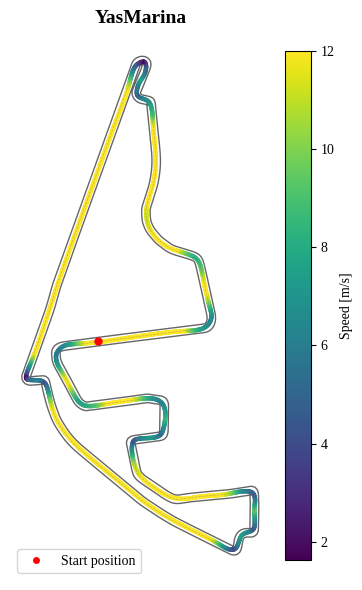

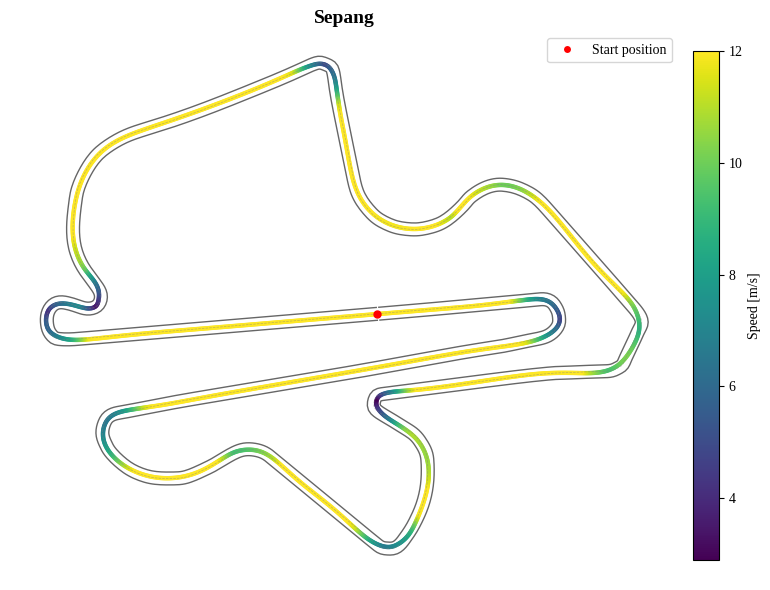

In [14]:
# --- Individual track plots with raceline speed + track boundaries + start position ---

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Liberation Serif', 'DejaVu Serif']

for name in track_names:
    td = tracks_data[name]
    cl = td["centerline"]
    rl = td["raceline"]

    fig, ax = plt.subplots(figsize=(8, 6))

    # Track boundaries
    ax.plot(td["x_left"], td["y_left"], 'k-', linewidth=1.0, alpha=0.6)
    ax.plot(td["x_right"], td["y_right"], 'k-', linewidth=1.0, alpha=0.6)

    # Raceline colored by speed
    sc = ax.scatter(rl[:, 1], rl[:, 2], c=rl[:, 5], cmap='viridis', s=5, zorder=2)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label('Speed [m/s]')

    # Centerline (dashed)
    ax.plot(cl[:, 0], cl[:, 1], '--', color='gray', linewidth=0.5, alpha=0.5)

    # Start position: star marker + heading arrow
    sx, sy, stheta = td["sx"], td["sy"], td["stheta"]
    ax.plot(sx, sy, 'o', color='red', markersize=5, zorder=5)

    for side in ['top', 'right', 'left', 'bottom']:
        ax.spines[side].set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(name, fontsize=14, fontweight='bold')

    from matplotlib.lines import Line2D
    legend_handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=6, label='Start position')]
    ax.legend(handles=legend_handles, loc='best')

    plt.tight_layout()
    plt.show()


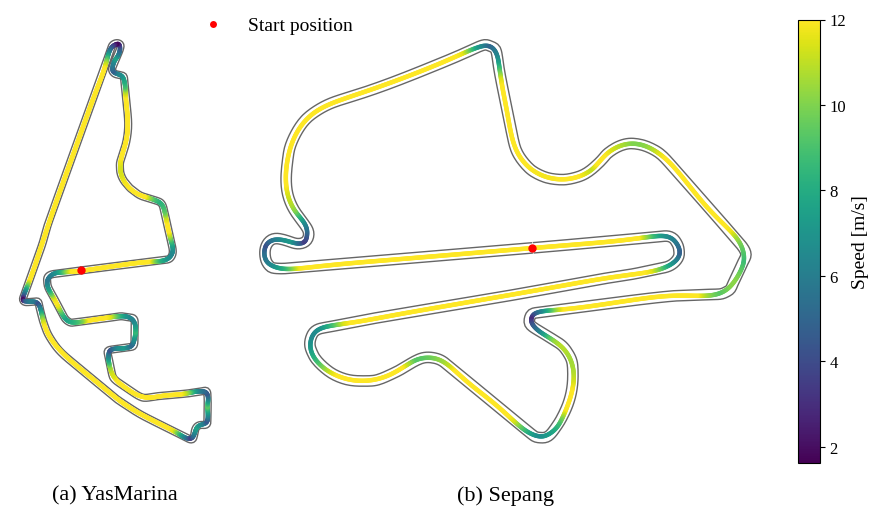

In [15]:
# --- Side-by-side plot for paper (both tracks) ---
from matplotlib.lines import Line2D

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Liberation Serif', 'DejaVu Serif']
label_fontsize = 16

# Shared speed color scale
vmin = min(tracks_data[n]["raceline"][:, 5].min() for n in track_names)
vmax = max(tracks_data[n]["raceline"][:, 5].max() for n in track_names)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

letters = ['(a)', '(b)']
sc_last = None

for ax, letter, name in zip(axes, letters, track_names):
    td = tracks_data[name]
    cl = td["centerline"]
    rl = td["raceline"]

    # Track boundaries
    ax.plot(td["x_left"], td["y_left"], 'k-', linewidth=1.0, alpha=0.6)
    ax.plot(td["x_right"], td["y_right"], 'k-', linewidth=1.0, alpha=0.6)

    # Raceline colored by speed
    sc = ax.scatter(rl[:, 1], rl[:, 2], c=rl[:, 5], cmap='viridis', s=5,
                    vmin=vmin, vmax=vmax, zorder=2)
    sc_last = sc

    # Start position: star marker + heading arrow
    sx, sy, stheta = td["sx"], td["sy"], td["stheta"]
    ax.plot(sx, sy, 'o', color='red', markersize=5, zorder=5)

    # Style
    for side in ['top', 'right', 'left', 'bottom']:
        ax.spines[side].set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect('equal', adjustable='box')

    # Label
    ax.annotate(f"{letter} {name}", xy=(0.5, -0.05), xycoords='axes fraction',
                ha='center', va='top', fontsize=label_fontsize)

# Shared colorbar
cbar = fig.colorbar(sc_last, ax=axes.ravel().tolist(), fraction=0.03, pad=0.02)
cbar.set_label('Speed [m/s]', fontsize=14)
cbar.ax.tick_params(labelsize=12)

# Legend for start position
legend_handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=6, label='Start position')]
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 1.02),
           frameon=False, prop={'size': 14})

plt.show()


In [16]:
fig.savefig('../plotting_code/figs/track_maps_with_raceline.pdf', format='pdf', bbox_inches='tight')
print("Saved to plotting_code/figs/track_maps_with_raceline.pdf")


Saved to plotting_code/figs/track_maps_with_raceline.pdf
